# Bayes Filter Occupancy Demo

Develop a Bayes filter that determines a room occupancy status from a PIR sensor and a mmWave sensor. Compare to the simpler rule-based sensor fusion output. Press `shift + enter` to run each cell.

In [1]:
import numpy as np

from utils import load_recording, plot_timeline, confusion_matrix, print_confusion_matrix

## Settings

In [16]:
# Recordings (folders containing occ.csv and meta.json)
CAL_RECORDING = "recordings/desk_work_calibration"
TEST_RECORDING = "recordings/desk_work_test"

# Desired sample rate (must be multiple of log sample rate, 0.1 s)
FILTER_DT_S = 1.0

# Sensors stay on a few seconds after leaving room, so extend truth some
EXTEND_TRUTH_S = 3.0

# Prevent perfect TPR or FPR (avoid divide by 0 error)
LIKELIHOOD_MIN = 0.001

## Analyze Raw Sensor Data

Downsample 10 Hz sample readings to 1 Hz, plot the raw sensor readings to see false positives and false negatives, and then calculate the hit/false alarm rates to use in the Bayes filter calculations.

In [3]:
# Load raw sample data
rec, meta = load_recording(CAL_RECORDING)
dt_log = meta["config"]["sample_interval_us"] * 1e-6
print(f"Period: {dt_log:.2f} sec")
print(f"Num samples: {rec['t'].shape}")

Period: 0.10 sec
Num samples: (9001,)


In [4]:
# Downsample (decimate) log to 1 sample per sec
step = round(FILTER_DT_S / dt_log)
dec = {name: values[::step] for name, values in rec.items()}
print(f"Period: {FILTER_DT_S} sec")
print(f"Num samples: {dec['t'].shape}")

Period: 1.0 sec
Num samples: (901,)


In [5]:
# Extend truth signal to avoid sensor false positives
n_after = round(EXTEND_TRUTH_S / FILTER_DT_S)
ext_truth = dec["truth"].copy()
for i in np.flatnonzero(ext_truth==1):
    ext_truth[i:i + n_after + 1] = 1

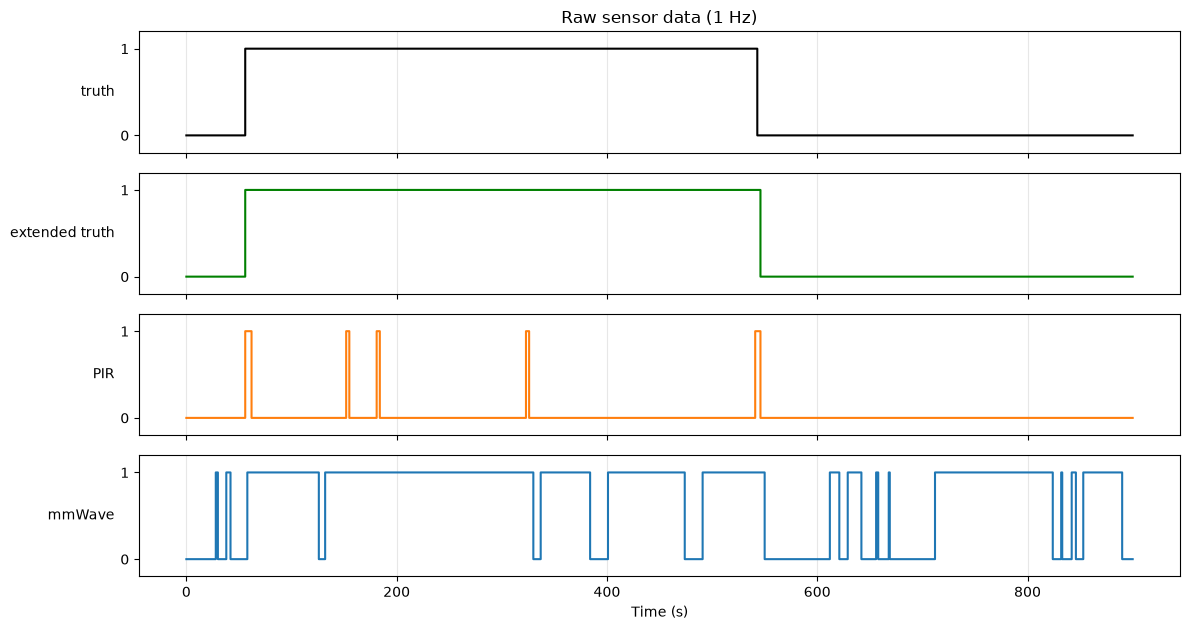

In [6]:
# Plot ground truth vs. raw sensor readings
plot_timeline(
    dec["t"], 
    [
        ("truth", dec["truth"], "k"),
        ("extended truth", ext_truth, "g"),
        ("PIR", dec["pir"], "tab:orange"),
        ("mmWave", np.clip(dec["mmwave"], 0, None), "tab:blue"),
    ], 
    title="Raw sensor data (1 Hz)",
)

In [11]:
# Print confusion matrix for PIR sensor
cm_pir = confusion_matrix(dec["pir"], ext_truth)
print_confusion_matrix("PIR", cm_pir)

PIR
                 sensor=1  sensor=0
  truth=occupied       20       470
  truth=empty           0       411


In [12]:
# Print confusion matrix for mmWave sensor
cm_mmwave = confusion_matrix(dec["mmwave"], ext_truth)
print_confusion_matrix("mmWave", cm_mmwave)

mmWave
                 sensor=1  sensor=0
  truth=occupied      441        49
  truth=empty         189       222


## Calibrate: Likelihoods

We need to calculate a few likelihoods from the sensor calibration data to use in our filter.

 * P(sensor = 1 | occupied) = TPR (hit rate)
 * P(sensor = 1 | empty) = FPR (false alarm rate)

In [19]:
def calc_likelihoods(cm):
    """Calculate (P(1 | occupied), P(1 | empty)) from a confusion matrix"""
    (tp, fn), (fp, tn) = cm

    # Hit rate (TPR)
    p1_occ = tp / (tp + fn)

    # False alarm rate (FPR)
    p1_emp = fp / (fp + tn)

    # Avoid 0 and 1, which would make one reading infinitely strong evidence
    p1_occ = np.clip(p1_occ, LIKELIHOOD_MIN, 1 - LIKELIHOOD_MIN)
    p1_emp = np.clip(p1_emp, LIKELIHOOD_MIN, 1 - LIKELIHOOD_MIN)

    return p1_occ, p1_emp

In [25]:
# Calculate likelihoods for PIR and mmWave sensors
p1_occ_pir, p1_emp_pir = calc_likelihoods(cm_pir)
p1_occ_mmwave, p1_emp_mmwave = calc_likelihoods(cm_mmwave)

# Print likelihoods
print(f"PIR:    P(1|occ)={p1_occ_pir:.3f} P(1|empty)={p1_emp_pir:.3f}")
print(f"mmWave: P(1|occ)={p1_occ_mmwave:.3f} P(1|empty)={p1_emp_mmwave:.3f}")

PIR:    P(1|occ)=0.041 P(1|empty)=0.001
mmWave: P(1|occ)=0.900 P(1|empty)=0.460


np.int64(20)